This script demonstrates how to build, evaluate, and use ML classification models to predict laundering activity.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [2]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/data?select=HI-Small_accounts.csv
    
# Load engineered AML dataset
# see 00. for CSV build
model_df = pd.read_csv(
    data_dir / 'aml_model_data.csv',
    parse_dates=['Timestamp']
)

print('Shape:', model_df.shape)
print('\nColumns:')
print(model_df.columns.tolist())

model_df.head()

Shape: (5077237, 20)

Columns:
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering', 'transaction_date', 'amount_difference', 'amount_difference_pct', 'hour', 'day_of_week', 'is_weekend', 'amount_paid_log', 'amount_received_log', 'same_currency']


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,transaction_date,amount_difference,amount_difference_pct,hour,day_of_week,is_weekend,amount_paid_log,amount_received_log,same_currency
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,8.215639,8.215639,1
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,2022-09-01,0.0,0.0,0,3,0,0.009950,0.009950,1
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,9.594008,9.594008,1
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,7.940217,7.940217,1
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,10.510095,10.510095,1


# Explore

In [3]:
# Examine target distribution
target_counts = model_df['Is Laundering'].value_counts()

print(target_counts)
print('\nClass percentages:')
print((model_df['Is Laundering'].value_counts(normalize=True) * 100).round(4))
print("""
Class imbalance is preset and must be addressed during modeling.
""")

Is Laundering
0    5072715
1       4522
Name: count, dtype: int64

Class percentages:
Is Laundering
0    99.9109
1     0.0891
Name: proportion, dtype: float64

Class imbalance is preset and must be addressed during modeling.



# Features

In [4]:
# Separate target and predictors
target = 'Is Laundering'

X = model_df.drop(columns=[target])
y = model_df[target]

# Identify feature types
categorical_features = X.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['number']
).columns.tolist()

# Treat bank IDs as categorical
bank_features = ['From Bank', 'To Bank']

for col in bank_features:
    if col in numerical_features:
        numerical_features.remove(col)
        categorical_features.append(col)

# Exclude identifiers and timestamp from initial predictors
exclude_features = [
    'Timestamp', 'Account', 'Account.1'
]

categorical_features = [
    col for col in categorical_features
    if col not in exclude_features
]

numerical_features = [
    col for col in numerical_features
    if col not in exclude_features
]

print('Categorical features:', categorical_features)
print('\nNumerical features:', numerical_features)

Categorical features: ['Receiving Currency', 'Payment Currency', 'Payment Format', 'transaction_date', 'From Bank', 'To Bank']

Numerical features: ['Amount Received', 'Amount Paid', 'amount_difference', 'amount_difference_pct', 'hour', 'day_of_week', 'is_weekend', 'amount_paid_log', 'amount_received_log', 'same_currency']


# Feature inspection

In [5]:
# Check missing values
missing_values = (
    model_df[X.columns.tolist() + [target]]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

if len(missing_values[missing_values > 0]):
    raise Exception()

In [6]:
# Inspect numerical features
print('Numerical feature summary:')
print(X[numerical_features].describe().T)

# Inspect categorical cardinality
print('\nCategorical feature cardinality:')
print(X[categorical_features].nunique().sort_values(ascending=False))

Numerical feature summary:
                           count          mean           std           min  \
Amount Received        5077237.0  5.989319e+06  1.037296e+09  1.000000e-06   
Amount Paid            5077237.0  4.509605e+06  8.698675e+08  1.000000e-06   
amount_difference      5077237.0 -1.479714e+06  5.577566e+08 -6.179892e+11   
amount_difference_pct  5077237.0 -2.290056e+02  1.507890e+05 -1.253799e+08   
hour                   5077237.0  1.049223e+01  7.362992e+00  0.000000e+00   
day_of_week            5077237.0  2.993646e+00  1.517596e+00  0.000000e+00   
is_weekend             5077237.0  1.227315e-01  3.281288e-01  0.000000e+00   
amount_paid_log        5077237.0  7.415072e+00  3.369475e+00  9.999995e-07   
amount_received_log    5077237.0  7.418564e+00  3.386996e+00  9.999995e-07   
same_currency          5077237.0  9.858626e-01  1.180574e-01  0.000000e+00   

                              25%         50%           75%           max  
Amount Received        183.300000  141

# Prep for split

In [7]:
# inspect daily transaction volume
daily_counts = (
    model_df.groupby(model_df['Timestamp'].dt.date)
    .size()
)

print('Date range:', model_df['Timestamp'].min(),
      'to', model_df['Timestamp'].max())

print(daily_counts.tail(15))

Date range: 2022-09-01 00:00:00 to 2022-09-10 23:59:00
Timestamp
2022-09-01    1114921
2022-09-02     754449
2022-09-03     207382
2022-09-04     207430
2022-09-05     482650
2022-09-06     482089
2022-09-07     482751
2022-09-08     482773
2022-09-09     654467
2022-09-10     208325
dtype: int64


In [8]:
# Find chronological cutoff closest to 80/20 split,
# while minimizing the difference in laundering rates;
# we need to split chronologically, yes, but we also need to consider the proportion
# of laundering to legitimate in train vs test; i.e. they should be close

split_results = []

for cutoff in daily_counts.index[1:]:
    train_mask_temp = model_df['Timestamp'].dt.date < cutoff
    test_mask_temp = ~train_mask_temp

    train_rate = model_df.loc[train_mask_temp, target].mean()
    test_rate = model_df.loc[test_mask_temp, target].mean()

    train_size = train_mask_temp.mean()

    split_results.append({
        'cutoff': cutoff,
        'train_size': train_size,
        'train_rate': train_rate,
        'test_rate': test_rate,
        'rate_difference': abs(train_rate - test_rate),
        'split_difference': abs(train_size - 0.80)
    })

split_results = pd.DataFrame(split_results)

# Prioritize an 80/20 split, then compare prevalence
split_results['score'] = (
    split_results['split_difference'] +
    split_results['rate_difference']
)

print(
    split_results.sort_values('score').head(10)
)

       cutoff  train_size  train_rate  test_rate  rate_difference  \
7  2022-09-09    0.830067    0.000846   0.001108         0.000262   
6  2022-09-08    0.734981    0.000811   0.001111         0.000300   
8  2022-09-10    0.958969    0.000838   0.002122         0.001284   
5  2022-09-07    0.639899    0.000779   0.001090         0.000311   
4  2022-09-06    0.544948    0.000722   0.001092         0.000370   
3  2022-09-05    0.449887    0.000669   0.001072         0.000403   
2  2022-09-04    0.409032    0.000540   0.001133         0.000594   
1  2022-09-03    0.368186    0.000391   0.001182         0.000792   
0  2022-09-02    0.219592    0.000289   0.001060         0.000771   

   split_difference     score  
7          0.030067  0.030329  
6          0.065019  0.065319  
8          0.158969  0.160253  
5          0.160101  0.160411  
4          0.255052  0.255421  
3          0.350113  0.350516  
2          0.390968  0.391562  
1          0.431814  0.432605  
0          0.580408  

In [9]:
print("""
The September 9 cutoff is the strongest candidate. It gives us:
- Training: 83.0% of transactions
- Test: 17.0% of transactions
- Training laundering rate: 0.0846%
- Test laundering rate: 0.1108%
- Relative difference in prevalence: approximately 31%
""")


The September 9 cutoff is the strongest candidate. It gives us:
- Training: 83.0% of transactions
- Test: 17.0% of transactions
- Training laundering rate: 0.0846%
- Test laundering rate: 0.1108%
- Relative difference in prevalence: approximately 31%



# Split (one of two)
Split into X_train, X-test, y_train, y_test

In [10]:




cutoff_date = pd.Timestamp('2022-09-09') # <--------------- Final chronological split




train_mask = model_df['Timestamp'] < cutoff_date
test_mask = ~train_mask

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print('Training:', X_train.shape)
print('Test:', X_test.shape)

print('\nTraining laundering rate:', round(y_train.mean() * 100, 4), '%')
print('Test laundering rate:', round(y_test.mean() * 100, 4), '%')

Training: (4214445, 19)
Test: (862792, 19)

Training laundering rate: 0.0846 %
Test laundering rate: 0.1108 %


# Split (two of two)
Use X_train, and carve out a third set, a validation set.

In [11]:
# Create chronological training/validation split.
# The original test set remains untouched for final evaluation.

# Use the 80th percentile of training timestamps as the cutoff.
# This reserves approximately the most recent 20% of the training
# period for validation, while preserving chronological order.
validation_cutoff = X_train['Timestamp'].quantile(0.80)

# Transactions before the cutoff are used to fit the models.
# Transactions on or after the cutoff are reserved for validation.
# This simulates predicting future transactions using historical data.
train_inner_mask = X_train['Timestamp'] < validation_cutoff
validation_mask = ~train_inner_mask

# Create separate feature and target datasets for each period.
X_train_final = X_train.loc[train_inner_mask].copy()
X_val = X_train.loc[validation_mask].copy()

y_train_final = y_train.loc[train_inner_mask].copy()
y_val = y_train.loc[validation_mask].copy()

# Inspect split sizes to confirm the approximate proportions.
print('Model training:', X_train_final.shape)
print('Validation:', X_val.shape)
print('Final test:', X_test.shape)

# Compare laundering prevalence across all three periods.
# We expect some variation because we are preserving the natural
# chronological distribution rather than artificially balancing classes.
# Large differences could indicate temporal changes in the data.
print('\nLaundering rates:')
print('Model training:', round(y_train_final.mean() * 100, 4), '%')
print('Validation:', round(y_val.mean() * 100, 4), '%')
print('Final test:', round(y_test.mean() * 100, 4), '%')

Model training: (3371534, 19)
Validation: (842911, 19)
Final test: (862792, 19)

Laundering rates:
Model training: 0.0775 %
Validation: 0.1131 %
Final test: 0.1108 %


# Modeling

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Standardize numerical features so variables with larger
# magnitudes do not disproportionately influence Logistic Regression.
numeric_transformer = StandardScaler()

# One-hot encode categorical features into binary indicator columns.
# Ignore categories that appear in validation but not training.
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Apply the appropriate preprocessing to each feature group.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

## Baseline
Create a simple model for a baseline.  
Predict every transaction as legitimate.

What we expect: Accuracy will be close to 99.9%, but recall for laundering it will be very near 0% (due to extreme class imbalance).

This gives us a useful benchmark. Our actual models need to detect laundering cases, not simply reproduce the majority class.

In [14]:
from sklearn.metrics import confusion_matrix

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
import numpy as np

# Establish a naive baseline by predicting every transaction
# as legitimate (class 0), regardless of its actual characteristics.
y_pred_baseline = np.zeros(len(y_val), dtype=int)

# Evaluate baseline accuracy.
# Accuracy can be misleading with extreme class imbalance.
baseline_accuracy = accuracy_score(y_val, y_pred_baseline)

# Generate confusion matrix.
# Rows represent actual classes; columns represent predicted classes.
baseline_cm = confusion_matrix(y_val, y_pred_baseline)

print(f'Baseline accuracy: {baseline_accuracy:.4%}')

m = average_precision_score(y_val, y_pred_baseline)
n = roc_auc_score(y_val, y_pred_baseline)

print(f'PR-AUC: {m}')
print(f'ROC-AUC: {n}')

result_dict['Naive Baseline'] = [m, n]

Baseline accuracy: 99.8869%
PR-AUC: 0.00113060572231232
ROC-AUC: 0.5


## Logistic regression
Logistic Regression is a good starting point for AML because it gives us an interpretable baseline for a binary classification problem.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and classification into one pipeline.
# The preprocessor standardizes numerical features and one-hot encodes
# categorical features before passing them to the classifier.
logistic_model = Pipeline([
    ('preprocessor', preprocessor),

    # Balanced class weights increase the penalty for misclassifying
    # minority-class laundering transactions.
    # Max iterations is increased to give the optimizer more time to converge.
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

In [16]:
# Fit the preprocessing transformations and Logistic Regression model.
# The preprocessor learns scaling parameters and categorical encodings
# exclusively from the training data.
# The classifier then learns the relationship between the predictors
# and laundering labels using the transformed training features.

logistic_model.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Timestamp','From Bank','Account',...,'amount_paid_log', 'amount_received_log','same_currency']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [17]:
# Generate predicted probabilities for each validation transaction.
# Column 1 represents the estimated probability of laundering (class 1).
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

# Generate default binary predictions using the 0.50 threshold.
# We'll evaluate this threshold first, then consider alternatives.
y_val_pred = logistic_model.predict(X_val)

In [18]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Evaluate precision, recall, and F1 for each class.
# Precision measures how many flagged transactions are actually laundering.
# Recall measures how many actual laundering transactions are detected.
# F1 balances precision and recall.
print(classification_report(
    y_val,
    y_val_pred,
    target_names=['Legitimate', 'Laundering'],
    digits=4,
    zero_division=0
))

# Calculate ranking metrics using predicted probabilities.
# PR-AUC (average precision) is especially useful for rare positive classes.
# ROC-AUC measures how well the model ranks positive cases above negatives.
m = average_precision_score(y_val, y_val_proba)
n = roc_auc_score(y_val, y_val_proba)
print(f'PR-AUC: {m}')
print(f'ROC-AUC: {n}')

result_dict['Logistic'] = [m, n]

              precision    recall  f1-score   support

  Legitimate     0.9996    0.8728    0.9319    841958
  Laundering     0.0061    0.6946    0.0122       953

    accuracy                         0.8726    842911
   macro avg     0.5029    0.7837    0.4720    842911
weighted avg     0.9985    0.8726    0.9309    842911

PR-AUC: 0.01121956981883361
ROC-AUC: 0.8853120119470085


In [19]:
print("""
ROC AUC: True Positive Rate vs. False Positive Rate
PR AUC: Precision vs. Recall

The class imbalance is present in the results.
Below, we use a brute force/grid search method to find the best threshold.
""")


ROC AUC: True Positive Rate vs. False Positive Rate
PR AUC: Precision vs. Recall

The class imbalance is present in the results.
Below, we use a brute force/grid search method to find the best threshold.



## Optimization...
...Loop through prediction class probabilities of the logistic regression model, and record model metrics.  
Altering the prediction threshold is one way to address class imbalance.

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Evaluate model performance across different probability thresholds.
# A transaction is flagged when its predicted laundering probability
# meets or exceeds the selected threshold.

thresholds = np.arange(0.05, 0.96, 0.05)

threshold_results = []

for threshold in thresholds:

    # Convert predicted probabilities into binary classifications.
    y_pred_threshold = (y_val_proba >= threshold).astype(int)

    # Calculate detection and alert metrics.
    precision = precision_score(
        y_val, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred_threshold, zero_division=0
    )

    # Count total transactions flagged for investigation.
    alerts = y_pred_threshold.sum()

    threshold_results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'alerts': alerts,
        'alert_rate': alerts / len(y_val) * 100
    })

threshold_results = pd.DataFrame(threshold_results)

print(threshold_results.round(4).to_string(index=False))

 threshold  precision  recall     f1  alerts  alert_rate
      0.05     0.0048  0.8311 0.0095  166142     19.7105
      0.10     0.0051  0.8069 0.0102  149408     17.7252
      0.15     0.0054  0.7880 0.0106  140196     16.6324
      0.20     0.0055  0.7744 0.0110  133732     15.8655
      0.25     0.0056  0.7608 0.0112  128581     15.2544
      0.30     0.0058  0.7492 0.0114  124060     14.7180
      0.35     0.0059  0.7377 0.0116  119904     14.2250
      0.40     0.0059  0.7209 0.0118  115860     13.7452
      0.45     0.0060  0.7041 0.0119  111848     13.2693
      0.50     0.0061  0.6946 0.0122  107777     12.7863
      0.55     0.0063  0.6810 0.0124  103584     12.2888
      0.60     0.0064  0.6684 0.0127   99156     11.7635
      0.65     0.0066  0.6537 0.0131   94260     11.1827
      0.70     0.0069  0.6432 0.0137   88791     10.5339
      0.75     0.0072  0.6201 0.0142   82330      9.7673
      0.80     0.0076  0.5981 0.0150   74802      8.8742
      0.85     0.0082  0.5687 0

In [21]:
min_precision = threshold_results['precision'].min() * 100
max_precision = threshold_results['precision'].max() * 100

max_recall = threshold_results['recall'].max() * 100
min_recall = threshold_results['recall'].min() * 100

min_alerts = threshold_results['alerts'].min()
max_alerts = threshold_results['alerts'].max()

print(f"""
The threshold analysis shows a tradeoff:
increasing the classification threshold improves precision
({min_precision:.2f}% to {max_precision:.2f}%)
but reduces recall ({max_recall:.2f}% to {min_recall:.2f}%).

Across the thresholds tested, the model generates between
{min_alerts:,} and {max_alerts:,} alerts.

This suggests that the model may still generate an impractically
high volume of false-positive alerts, even at higher thresholds.

Next steps
Understand the financial and temporal effects of the varying false-positive rates.
""")


The threshold analysis shows a tradeoff:
increasing the classification threshold improves precision
(0.48% to 1.15%)
but reduces recall (83.11% to 42.08%).

Across the thresholds tested, the model generates between
34,799 and 166,142 alerts.

This suggests that the model may still generate an impractically
high volume of false-positive alerts, even at higher thresholds.

Next steps
Understand the financial and temporal effects of the varying false-positive rates.



## Random forest
- Logistic Regression: Models a linear relationship between features and the probability of laundering.
- Random Forest: Combines multiple decision trees to capture nonlinear relationships and feature interactions.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

# Sample the training data without changing its class distribution.
X_rf_train = X_train_final.sample(
    n=min(500_000, len(X_train_final)),
    random_state=42
)

y_rf_train = y_train_final.loc[X_rf_train.index]

# Build the Random Forest pipeline.
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=10,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

# Fit on the sampled training data.
rf_pipeline.fit(X_rf_train, y_rf_train)

# Generate validation probabilities.
y_val_proba_rf = rf_pipeline.predict_proba(X_val)[:, 1]

# Generate binary predictions using the default threshold.
y_val_pred_rf = (y_val_proba_rf >= 0.5).astype(int)

# Evaluate classification performance.
print(classification_report(
    y_val,
    y_val_pred_rf,
    target_names=['Legitimate', 'Laundering'],
    digits=4,
    zero_division=0
))

# Calculate ranking metrics.
m = average_precision_score(y_val, y_val_proba_rf)
n = roc_auc_score(y_val, y_val_proba_rf)

result_dict['Random Forest'] = [m, n]

print(f'PR-AUC: {m:.4f}')
print(f'ROC-AUC: {n:.4f}')

              precision    recall  f1-score   support

  Legitimate     0.9998    0.9326    0.9650    841958
  Laundering     0.0136    0.8206    0.0267       953

    accuracy                         0.9325    842911
   macro avg     0.5067    0.8766    0.4959    842911
weighted avg     0.9987    0.9325    0.9640    842911

PR-AUC: 0.0412
ROC-AUC: 0.9260


In [23]:
rf_precision = precision_score(y_val, y_val_pred_rf)
rf_recall = recall_score(y_val, y_val_pred_rf)
rf_false_positive_rate = 1 - rf_precision

print(f"""
Interpretation: Random Forest achieves a PR-AUC of
{average_precision_score(y_val, y_val_proba_rf):.4f}
and a ROC-AUC of {roc_auc_score(y_val, y_val_proba_rf):.4f}.

At the 0.5 threshold, it achieves {rf_precision * 100:.2f}% precision
and {rf_recall * 100:.2f}% recall.

Approximately {rf_false_positive_rate * 100:.1f}% of flagged transactions
are false positives.

The model shows promise, but threshold tuning and further
hyperparameter optimization are still needed.
""")


Interpretation: Random Forest achieves a PR-AUC of
0.0412
and a ROC-AUC of 0.9260.

At the 0.5 threshold, it achieves 1.36% precision
and 82.06% recall.

Approximately 98.6% of flagged transactions
are false positives.

The model shows promise, but threshold tuning and further
hyperparameter optimization are still needed.



## Feature importance analysis (example)
Using trained random forest model.

In [25]:
# Extract fitted preprocessing and classifier.
fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["classifier"]

# Get feature names after preprocessing (including one-hot encoding).
feature_names = fitted_preprocessor.get_feature_names_out()



display(feature_importances.head(20))

NameError: name 'feature_importances' is not defined

In [27]:
# Get fitted Random Forest components.
rf_preprocessor = rf_pipeline.named_steps['preprocessor']
rf_classifier = rf_pipeline.named_steps['classifier']

# Get feature names after preprocessing.
feature_names = rf_preprocessor.get_feature_names_out()

# Build feature importance DataFrame.
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_classifier.feature_importances_
})

# Remove preprocessing prefixes and aggregate one-hot encoded features.
importance_df['original_feature'] = (
    importance_df['feature']
    .str.replace(r'^(num|cat)__', '', regex=True)
    .str.split('_')
    .str[0]
)

importance_summary = (
    importance_df.groupby('original_feature')['importance']
    .sum()
    .sort_values(ascending=False)
)

# Display top 20 original features.
print(importance_summary.head(20))

original_feature
Payment Format        0.291139
To Bank               0.182644
From Bank             0.164945
amount                0.137039
transaction           0.081044
Payment Currency      0.032042
Receiving Currency    0.030839
day                   0.021020
hour                  0.018838
is                    0.015806
Amount Paid           0.010152
Amount Received       0.008772
same                  0.005720
Name: importance, dtype: float64


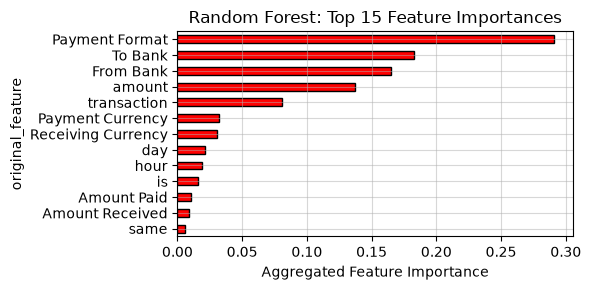


Next steps...
Retrain the random forest model on the top N features



In [28]:
# Plot top 15 original features.
importance_summary.head(15).sort_values().plot(
    kind='barh',
    figsize=(6, 3),
    title='Random Forest: Top 15 Feature Importances',
    color='red',
    edgecolor='black',
    lw=1
)

plt.grid(alpha=0.5)
plt.xlabel('Aggregated Feature Importance')
plt.tight_layout()
plt.show()

print("""
Next steps...
Retrain the random forest model on the top N features
""")

## Random forest hyperparameter tuning (example)
Here, we focus on two hyperparameters, when really there are many more.  
However, it becomes computationally expensive very quickly.

In [29]:
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'classifier__max_depth': [10, 20],
    'classifier__min_samples_leaf': [5, 10]
}

# Create a manageable tuning sample from the training period.
X_tune = X_train_final.sample(
    n=min(200_000, len(X_train_final)),
    random_state=42
).sort_index()

y_tune = y_train_final.loc[X_tune.index]

results = []

for params in ParameterGrid(param_grid):
    model = clone(rf_pipeline)
    model.set_params(
        classifier__n_estimators=100,
        **params
    )

    model.fit(X_tune, y_tune)

    val_proba = model.predict_proba(X_val)[:, 1]

    m = average_precision_score(y_val, val_proba)
    n = roc_auc_score(y_val, val_proba)

    result_dict['Tuned RF ' + str(params)] = [m, n]

    results.append({
        **params,
        'pr_auc': m,
        'roc_auc': n
    })

results = pd.DataFrame(results)

print(results.sort_values('pr_auc', ascending=False).to_string(index=False))

 classifier__max_depth  classifier__min_samples_leaf   pr_auc  roc_auc
                    20                            10 0.030153 0.920890
                    10                            10 0.027278 0.908527
                    20                             5 0.027164 0.915234
                    10                             5 0.026024 0.908990


In [30]:
# Display the best hyperparameters.
best_result = results.loc[results['pr_auc'].idxmax()]

print('Best parameters:')
print(best_result[['classifier__max_depth',
                   'classifier__min_samples_leaf']])

# Display the best validation scores.
print(f"\nBest Validation PR-AUC: {best_result['pr_auc']:.4f}")
print(f"Best Validation ROC-AUC: {best_result['roc_auc']:.4f}")

Best parameters:
classifier__max_depth           20.0
classifier__min_samples_leaf    10.0
Name: 3, dtype: float64

Best Validation PR-AUC: 0.0302
Best Validation ROC-AUC: 0.9209


## LightGBM
Random forest is a bagging technique; it takes the mean of many models.   
LightGBM is a different technique, a gradient boosting machine.  
A GBM learns from its previous errors.  
Thus, LightGBM is a boosting technique.

In [31]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

# Calculate class imbalance weight from training data.
scale_pos_weight = (
    (y_train_final == 0).sum() /
    (y_train_final == 1).sum()
)

# Build LightGBM pipeline.
lgbm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        objective='binary',
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Fit model.
lgbm_model.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Timestamp','From Bank','Account',...,'amount_paid_log', 'amount_received_log','same_currency']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [32]:
# Generate predicted probabilities.
y_val_proba_lgbm = lgbm_model.predict_proba(X_val)[:, 1]

# Generate binary predictions using the default threshold.
y_val_pred_lgbm = (y_val_proba_lgbm >= 0.5).astype(int)

              precision    recall  f1-score   support

  Legitimate     0.9997    0.8372    0.9112    841958
  Laundering     0.0055    0.7975    0.0109       953

    accuracy                         0.8371    842911
   macro avg     0.5026    0.8173    0.4611    842911
weighted avg     0.9986    0.8371    0.9102    842911

PR-AUC: 0.0046
ROC-AUC: 0.8173


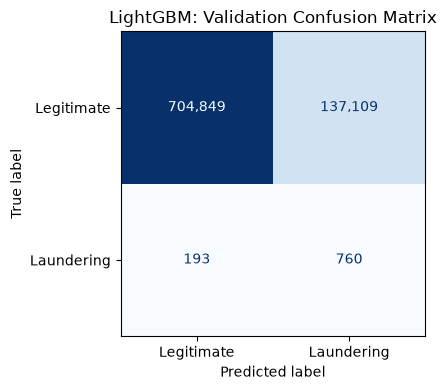

In [33]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score
)
import matplotlib.pyplot as plt

# Classification report at the default 0.5 threshold.
print(classification_report(
    y_val,
    y_val_pred_lgbm,
    target_names=['Legitimate', 'Laundering'],
    digits=4,
    zero_division=0
))

# Calculate evaluation metrics.
m = average_precision_score(y_val, y_val_proba_lgbm)
n = roc_auc_score(y_val, y_val_proba_lgbm)

result_dict['LightGBM'] = [m, n]

print(f'PR-AUC: {m:.4f}')
print(f'ROC-AUC: {n:.4f}')

# Display confusion matrix.
cm = confusion_matrix(y_val, y_val_pred_lgbm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Laundering']
)

fig, ax = plt.subplots(figsize=(6, 4))
display.plot(ax=ax, cmap='Blues', values_format=',d', colorbar=False)
ax.set_title('LightGBM: Validation Confusion Matrix')
plt.tight_layout()
plt.show()

In [34]:
print("""
LightGBM performed substantially worse than Random Forest.

However, the comparison isn't entirely fair: 
Random Forest was trained on a 500,000-row sample, 
while LightGBM used the full training set. 

Differences in training data and model configuration may explain some of the performance gap.

Next step: 
Tune LightGBM, then retrain both models on the same full training dataset for a controlled comparison.
""")


LightGBM performed substantially worse than Random Forest.

However, the comparison isn't entirely fair: 
Random Forest was trained on a 500,000-row sample, 
while LightGBM used the full training set. 

Differences in training data and model configuration may explain some of the performance gap.

Next step: 
Tune LightGBM, then retrain both models on the same full training dataset for a controlled comparison.



In [35]:
print("""

A note on models

SVM: 
Support Vector Machine
Can model nonlinear boundaries using kernels, 
but training on millions of transactions is computationally expensive. 
A linear SVM is more practical but may not capture complex patterns.

Neural Network (MLP): 
Multi-Layer Perceptron
Can learn nonlinear relationships and feature interactions, 
but requires more tuning, scaling, and architecture decisions. 
It may not outperform boosted trees on tabular data.

The next practical model is really XGBoost, another gradient boosting algorithm, similar to LightGBM.
""")



A note on models

SVM: 
Support Vector Machine
Can model nonlinear boundaries using kernels, 
but training on millions of transactions is computationally expensive. 
A linear SVM is more practical but may not capture complex patterns.

Neural Network (MLP): 
Multi-Layer Perceptron
Can learn nonlinear relationships and feature interactions, 
but requires more tuning, scaling, and architecture decisions. 
It may not outperform boosted trees on tabular data.

The next practical model is really XGBoost, another gradient boosting algorithm, similar to LightGBM.



## XGBoost

In [36]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Calculate class imbalance from the training sample.
scale_pos_weight = (
    (y_rf_train == 0).sum() /
    (y_rf_train == 1).sum()
)

# Build the XGBoost pipeline.
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        objective='binary:logistic',
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        scale_pos_weight=scale_pos_weight,
        eval_metric='aucpr',
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    ))
])

# Fit on the same sampled training data as Random Forest.
xgb_model.fit(X_rf_train, y_rf_train)

# Generate validation probabilities and predictions.
y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_val_pred_xgb = (y_val_proba_xgb >= 0.5).astype(int)

# Evaluate classification performance.
print(classification_report(
    y_val,
    y_val_pred_xgb,
    target_names=['Legitimate', 'Laundering'],
    digits=4,
    zero_division=0
))

# Calculate ranking metrics.
m = average_precision_score(y_val, y_val_proba_xgb)
n = roc_auc_score(y_val, y_val_proba_xgb)

result_dict['XGBoost'] = [m, n]

print(f'PR-AUC: {m:.4f}')
print(f'ROC-AUC: {n:.4f}')

              precision    recall  f1-score   support

  Legitimate     0.9998    0.9340    0.9658    841958
  Laundering     0.0136    0.8017    0.0267       953

    accuracy                         0.9338    842911
   macro avg     0.5067    0.8678    0.4962    842911
weighted avg     0.9986    0.9338    0.9647    842911

PR-AUC: 0.0430
ROC-AUC: 0.9578


# Model results compare

In [37]:
display_results = pd.DataFrame(
    result_dict,
    index=['PR-AUC', 'ROC-AUC']
).T.sort_values('PR-AUC', ascending=False)

In [38]:
display_results

,PR-AUC,ROC-AUC
XGBoost,0.043018,0.957829
Random Forest,0.041191,0.926019
"Tuned RF {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 10}",0.030153,0.920890
"Tuned RF {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 10}",0.027278,0.908527
"Tuned RF {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5}",0.027164,0.915234
"Tuned RF {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5}",0.026024,0.908990
Logistic,0.011220,0.885312
LightGBM,0.004625,0.817318
Naive Baseline,0.001131,0.500000


In [39]:
print("""
We prioritize PR-AUC because our dataset is extremely imbalanced: 
only about 0.1% of transactions are laundering.

- ROC-AUC: 
Measures how well the model distinguishes positive from negative cases across thresholds. 
It can look strong even when false positives are overwhelming.

- PR-AUC: 
Focuses on precision and recall for the positive class.
It shows how effectively the model identifies laundering without flagging excessive legitimate transactions.
For AML, false positives matter because every flagged transaction can require analyst investigation.

Bottom line: 
PR-AUC is more informative for selecting models in this project 
because detecting laundering while controlling false-positive alerts is the central challenge. 
ROC-AUC is still useful as a secondary metric.
""")


We prioritize PR-AUC because our dataset is extremely imbalanced: 
only about 0.1% of transactions are laundering.

- ROC-AUC: 
Measures how well the model distinguishes positive from negative cases across thresholds. 
It can look strong even when false positives are overwhelming.

- PR-AUC: 
Focuses on precision and recall for the positive class.
It shows how effectively the model identifies laundering without flagging excessive legitimate transactions.
For AML, false positives matter because every flagged transaction can require analyst investigation.

Bottom line: 
PR-AUC is more informative for selecting models in this project 
because detecting laundering while controlling false-positive alerts is the central challenge. 
ROC-AUC is still useful as a secondary metric.



In [40]:
# Identify the top-performing model by PR-AUC.
best_model = display_results.iloc[0]

print(f"""
Best Model: {display_results.index[0]}

PR-AUC: {best_model['PR-AUC']:.4f}
ROC-AUC: {best_model['ROC-AUC']:.4f}
""")


Best Model: XGBoost

PR-AUC: 0.0430
ROC-AUC: 0.9578



# Conclusion

In [41]:
print("""
Yes, we addressed class imbalance on the model level by setting the argument of class_weights=Balanced.

But we could also undersample the majority class,
or oversample the minority class,
or create synthetic data.

However, in my experience, doing so yields little value.

Instead, we could:
- Adjust classification threshold to reduce the number of flagged transactions.
- Improve feature engineering with account behavior, transaction velocity, and counterparty patterns.
- Segment customers and apply different risk thresholds to different customer groups.
- Incorporate investigator feedback to improve training labels.
- Aggregate related transactions into alerts rather than flagging each transaction individually.
""")


Yes, we addressed class imbalance on the model level by setting the argument of class_weights=Balanced.

But we could also undersample the majority class,
or oversample the minority class,
or create synthetic data.

However, in my experience, doing so yields little value.

Instead, we could:
- Adjust classification threshold to reduce the number of flagged transactions.
- Improve feature engineering with account behavior, transaction velocity, and counterparty patterns.
- Segment customers and apply different risk thresholds to different customer groups.
- Incorporate investigator feedback to improve training labels.
- Aggregate related transactions into alerts rather than flagging each transaction individually.



In [42]:
print('done')

done
